# 과제 4 — Diffusion Policy 학습 및 ACT 비교

**과제 내용**: 과제 3과 같은 데이터셋으로 Diffusion Policy를 학습하고, 실제 로봇에서 10회 평가해 과제 3의 ACT 정책과 성공률·동작의 부드러움·반응성을 비교한다. 같은 Diffusion Policy를 DDIM 스케줄러로 denoising 횟수만 10으로 줄여 10회 더 평가하고, denoising 횟수가 성공률과 실시간성에 주는 영향을 분석한다. 학습된 정책은 Huggingface Hub에 업로드한다.

### 실습 환경 — **LeRobot 0.6.0**
- Python 3.12 이상, PyTorch 2.7 이상이 필요하다.
- 실습 PC에는 `lerobot[all]==0.6.0`이 설치되어 있다. 개인 PC에서 하려면 같은 버전으로 설치한다.
  ```bash
  pip install "lerobot[all]==0.6.0"
  ```
  `all`에는 학습(wandb), 녹화·텔레오퍼레이션, SO-101 모터(feetech), Diffusion Policy, SmolVLA에 필요한 패키지가 모두 들어 있다. (0.6.0부터 extra 없이 `pip install lerobot`만 하면 학습·데이터셋 의존성이 빠지므로 주의)
- `lerobot-rollout`으로 녹화하는 평가 데이터셋은 이름이 **`rollout_`로 시작**해야 한다. `lerobot-record`와 `lerobot-rollout` 모두 새 데이터셋 이름 끝에 녹화 시각(`_YYYYMMDD_HHMMSS`)을 자동으로 붙이므로, 0절에는 **Hub에 실제로 올라간 이름**을 적는다.

### 작성 요령
- 이 노트북을 본인 GitHub 저장소(과제 1~3과 같은 저장소, assignments 폴더)에 `assignment_4.ipynb`로 올린다.
- 학습과 평가는 **터미널에서** 진행하고, 이 노트북에는 결과 확인 코드와 분석을 작성한다. (보고서를 노트북으로 작성하는 것이다.)
- 모든 코드 셀은 **실행한 뒤 출력 결과가 보이는 상태로** 커밋한다. (출력이 없으면 미제출로 간주)
- `[작성]` 표시가 있는 부분을 모두 채운다.

### 주의 사항
- Diffusion Policy는 과제 3의 ACT와 **같은 학습 데이터셋**으로 학습해야 한다. 1-3의 확인 셀에서 자동으로 검사한다.
- 비교 대상 ACT는 과제 3에서 성공률이 가장 높았던 chunk_size의 정책을 쓴다. 과제 3 이후 평가 환경(조명, 카메라 위치, 물체 위치 표시)이 바뀌지 않았다면 과제 3의 ACT 평가 결과를 **재사용해도 된다.** 바뀌었다면 ACT도 다시 10회 평가한다.
- 학습 데이터셋, 평가 데이터셋, 모델 repo는 모두 **public**으로 설정한다.
- 모델 가중치는 **Huggingface Hub에만** 올리고 GitHub에는 올리지 않는다. `.gitignore`에 `outputs/`가 있는지 확인할 것.
- **마감 시각 이후의 커밋은 반영하지 않는다.**

**작성자: 2021136029 김용현**

**이번 실험의 적용 범위와 작성 상태**
- 시뮬레이션 평가가 허용된 안내에 따라 Isaac Sim의 SO-101 과일→접시 작업으로 진행했다. 아래 원본의 실로봇 안내는 보존하고, 실제 사용한 시뮬레이션 절차를 각 절에 덧붙였다.
- 과제 3의 실물 큐브 데이터와 결과를 재사용하지 않았다. 새 시뮬레이션 시연 100개로 ACT와 Diffusion을 모두 학습하여 같은 데이터·초기 배치에서 비교했다. 따라서 원본의 ‘과제 3 데이터 그대로 재사용’ 조건과는 실험 구성이 다르다.
- 기본 평가 30회와 반응성 9회(필수 DP 6회＋ACT 참고 3회)를 완료했다. **영상 검수 후 작성자가 제시한 부드러움 점수는 ACT 4점, DDPM·DDIM10 각각 2점이다.** 조건별 대표 점수를 해당 조건의 10회에 동일 적용했으며, 회차별로 독립 채점한 차이를 뜻하지 않는다.
- HF 업로드를 완료했다. ACT·Diffusion 모델은 공개이고, 학습 100회·기본 평가 30회·반응성 9회 데이터는 비공개이다. 데이터는 저장소 소유자의 인증으로 접근·메타데이터를 확인했으며 익명 접근은 차단된다. 원본의 데이터 public 조건은 미충족으로 남겨 두었고, 비공개 자료를 검수하려면 별도의 읽기 권한이 필요하다. 웹 뷰어 재생은 미확인이다.


## 0. 제출 정보

학습 데이터: 딸기·오렌지·레몬·바나나 각 25회, 총 100회·57,038프레임·30fps. 입력은 `front`·`wrist` 640×480 영상과 6관절 상태이고 출력은 6관절 목표값이다.

실제 task 문장은 `Pick the strawberry and put it on the plate.`, `Pick the orange and put it on the plate.`, `Pick the lemon and put it on the plate.`, `Pick the banana and put it on the plate.`이다. 아래 `TASK`는 작업군의 대표 표현이며, 평가기는 회차의 과일에 맞는 문장을 사용했다.

로봇 베이스 위치·회전, 과일·접시 위치, 과일 방향, 조명에는 변화가 포함되어 있다. **시작 관절각은 100회 모두 `[0, -100, 90, 50, 0, -10]`도이며, 시작 관절각 랜덤화와 중간 물체 이동 시연은 포함하지 않았다.**


In [1]:
# [작성] 본인 정보로 수정
STUDENT_ID = "2021136029"
NAME = "김용현"
HF_USER = "alohateam1423"

TASK = "Pick the fruit and put it on the plate."   # 대표 표현; 실제 문장은 과일별 4종(위 설명)

TRAIN_DATASET = f"{HF_USER}/sim_fruit_100"   # 과제 3과 같은 학습 데이터셋 (0.6.0에서 녹화했다면 끝에 녹화 시각이 붙어 있다)

# 비교 대상 ACT 정책 (과제 3에서 성공률이 가장 높았던 chunk_size)
ACT_CHUNK_SIZE = 100
ACT_POLICY_REPO = f"{HF_USER}/act_sim_fruit100"

# Diffusion Policy
DP_POLICY_REPO = f"{HF_USER}/diffusion_sim_fruit100"

# 평가 데이터셋 — lerobot-rollout으로 녹화, 이름은 rollout_로 시작하고 끝에 녹화 시각이 붙는다.
# Hub에 실제로 올라간 이름을 그대로 적을 것 (ACT 평가를 재사용하면 과제 3의 평가 데이터셋 repo를 그대로 적는다)
CONDITIONS = ["act", "dp", "dp_ddim10"]
LABELS = {"act": f"ACT (chunk{ACT_CHUNK_SIZE})", "dp": "DP (DDPM)", "dp_ddim10": "DP (DDIM 10)"}
EVAL_DATASETS = {
    "act":       f"{HF_USER}/rollout_hw4_sim_act",
    "dp":        f"{HF_USER}/rollout_hw4_sim_dp",
    "dp_ddim10": f"{HF_USER}/rollout_hw4_sim_dp_ddim10",
}
WANDB_URL = "https://wandb.ai/launcher1423-/lerobot/runs/863fc2p0"   # 사용하지 않았다면 빈 문자열

# 실제 업로드된 HF ID. 모델은 public, 학습·평가 데이터는 private이다.
HUB_UPLOAD_CONFIRMED = True
from pathlib import Path
REPORT_DIR = next(p for p in (Path.cwd(), Path.cwd() / "assignments")
                  if (p / "evidence/hw4/summary.json").is_file())
EVIDENCE_DIR = REPORT_DIR / "evidence/hw4"
LOCAL_REPOS = {
    TRAIN_DATASET: EVIDENCE_DIR / "train_dataset",
    ACT_POLICY_REPO: EVIDENCE_DIR / "act_policy",
    DP_POLICY_REPO: EVIDENCE_DIR / "dp_policy",
    **{EVAL_DATASETS[k]: EVIDENCE_DIR / f"eval_{k}" for k in CONDITIONS},
}
print("현재 상태: 학습·평가·HF 업로드 완료 / 모델 public · 데이터 private")
print("아래는 실제 HF 주소입니다. 비공개 데이터 확인에는 소유자 또는 허용된 읽기 토큰이 필요합니다.")

print("학번/이름     :", STUDENT_ID, NAME)
print("태스크        :", TASK)
print("학습 데이터셋 :", f"https://huggingface.co/datasets/{TRAIN_DATASET}")
print("ACT 정책      :", f"https://huggingface.co/{ACT_POLICY_REPO}")
print("DP 정책       :", f"https://huggingface.co/{DP_POLICY_REPO}")
for k in CONDITIONS:
    print(f"{LABELS[k]:<14} 평가 :", f"https://huggingface.co/datasets/{EVAL_DATASETS[k]}")
print("wandb         :", WANDB_URL or "(미사용)")

print("ACT wandb     : https://wandb.ai/launcher1423-/lerobot/runs/ja1nrwqa")

REACTIVITY_DATASETS = {k: f"{HF_USER}/rollout_hw4_sim_{k}_reactivity" for k in CONDITIONS}
for k, rid in REACTIVITY_DATASETS.items():
    print(f"{LABELS[k]} 반응성(비공개): https://huggingface.co/datasets/{rid}")


현재 상태: 학습·평가·HF 업로드 완료 / 모델 public · 데이터 private
아래는 실제 HF 주소입니다. 비공개 데이터 확인에는 소유자 또는 허용된 읽기 토큰이 필요합니다.
학번/이름     : 2021136029 김용현
태스크        : Pick the fruit and put it on the plate.
학습 데이터셋 : https://huggingface.co/datasets/alohateam1423/sim_fruit_100
ACT 정책      : https://huggingface.co/alohateam1423/act_sim_fruit100
DP 정책       : https://huggingface.co/alohateam1423/diffusion_sim_fruit100
ACT (chunk100) 평가 : https://huggingface.co/datasets/alohateam1423/rollout_hw4_sim_act
DP (DDPM)      평가 : https://huggingface.co/datasets/alohateam1423/rollout_hw4_sim_dp
DP (DDIM 10)   평가 : https://huggingface.co/datasets/alohateam1423/rollout_hw4_sim_dp_ddim10
wandb         : https://wandb.ai/launcher1423-/lerobot/runs/863fc2p0
ACT wandb     : https://wandb.ai/launcher1423-/lerobot/runs/ja1nrwqa
ACT (chunk100) 반응성(비공개): https://huggingface.co/datasets/alohateam1423/rollout_hw4_sim_act_reactivity
DP (DDPM) 반응성(비공개): https://huggingface.co/datasets/alohateam1423/rollout_hw4_sim_dp_reactivity
DP (D

In [2]:
# LeRobot 버전 확인 — 학습·평가에 사용한 환경과 같은 커널에서 실행할 것
from importlib.metadata import version, PackageNotFoundError
try:
    LEROBOT_VERSION = version("lerobot")
except PackageNotFoundError:
    LEROBOT_VERSION = None
print("lerobot 버전:", LEROBOT_VERSION or "(이 커널에 설치되어 있지 않음)")
print("버전 확인   :", "통과" if LEROBOT_VERSION and LEROBOT_VERSION.startswith("0.6.") else "0.6.x가 아님 — 실습 환경을 확인할 것")

lerobot 버전: 0.6.0
버전 확인   : 통과


In [3]:
# Hub 접근 확인 — 6개 repo 모두 "OK"가 나와야 한다
import json
from huggingface_hub import HfApi, hf_hub_download

api = HfApi(token=True)
checks = [(TRAIN_DATASET, "dataset"), (ACT_POLICY_REPO, "model"), (DP_POLICY_REPO, "model")]
checks += [(EVAL_DATASETS[k], "dataset") for k in CONDITIONS]
for rid, rtype in checks:
    if not HUB_UPLOAD_CONFIRMED:
        print(f"미완료 [{rtype:7}] {rid} — HF 업로드 전; 원격 접근 확인은 아직 수행하지 않음")
        continue
    try:
        files = api.list_repo_files(rid, repo_type=rtype)
        visibility = "private" if api.repo_info(rid, repo_type=rtype).private else "public"
        print(f"OK   [{rtype:7}] {rid}  (파일 {len(files)}개, {visibility}, 현재 인증으로 확인)")
    except Exception as e:
        print(f"FAIL [{rtype:7}] {rid}  -> {type(e).__name__}: public 여부와 repo_id를 확인할 것")

C:\Users\kyhyg\OneDrive\바탕 화면\4학년\2학기\로봇제어인공지능01김성제\.venv-lerobot\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


OK   [dataset] alohateam1423/sim_fruit_100  (파일 20개, private, 현재 인증으로 확인)


OK   [model  ] alohateam1423/act_sim_fruit100  (파일 8개, public, 현재 인증으로 확인)


OK   [model  ] alohateam1423/diffusion_sim_fruit100  (파일 8개, public, 현재 인증으로 확인)


OK   [dataset] alohateam1423/rollout_hw4_sim_act  (파일 8개, private, 현재 인증으로 확인)


OK   [dataset] alohateam1423/rollout_hw4_sim_dp  (파일 8개, private, 현재 인증으로 확인)


OK   [dataset] alohateam1423/rollout_hw4_sim_dp_ddim10  (파일 8개, private, 현재 인증으로 확인)


## 1. 실험 설계

### 1-1. 배경
Diffusion Policy는 행동을 한 번에 회귀하지 않는다. 가우시안 노이즈에서 출발해 노이즈를 조금씩 걷어내며(denoising) 행동 시퀀스를 만든다. 학습할 때는 행동에 섞인 노이즈를 맞히도록 배우고, 추론할 때는 이 과정을 `num_inference_steps`번 반복한다.

- `n_obs_steps`: 정책에 넣는 과거 관측 프레임 수
- `horizon`: 한 번의 추론으로 생성하는 행동 시퀀스의 길이
- `n_action_steps`: 생성한 시퀀스 중 실제로 실행하는 스텝 수. 이만큼 실행한 뒤 다시 추론한다.

ACT와 비교하면 다음과 같다.
- ACT는 행동을 L1 손실로 직접 회귀한다. 같은 상황에서 시연이 여러 갈래로 나뉘면(예: 물체를 왼쪽에서 잡기도 하고 오른쪽에서 잡기도 함) 회귀 출력은 그 평균 쪽으로 끌려가기 쉽다. ACT는 CVAE 구조로 이 문제를 일부 완화한다.
- Diffusion Policy는 행동 분포에서 샘플링하므로 여러 갈래의 시연을 그대로 표현할 수 있다. 대신 추론할 때마다 denoising을 여러 번 반복해야 하므로 느리다.
- 학습에 쓴 DDPM 스케줄러 대신 DDIM 스케줄러를 쓰면 **재학습 없이** denoising 횟수를 줄여 추론을 빠르게 할 수 있다. 다만 횟수를 너무 줄이면 행동의 품질이 떨어질 수 있다.

아래 셀은 학습한 정책의 설정을 데이터셋의 fps로 환산해 초 단위로 보여준다.

In [4]:
# 학습 데이터셋의 fps로 관측·행동 구간 길이 환산
import pandas as pd
import matplotlib.pyplot as plt

def load_json(repo_id, filename, repo_type="model"):
    try:
        if not HUB_UPLOAD_CONFIRMED:
            path = LOCAL_REPOS[repo_id] / filename
            print(f"[로컬 메타데이터 확인 · HF 미업로드] {repo_id}/{filename}")
            return json.loads(path.read_text(encoding="utf-8"))
        return json.load(open(hf_hub_download(repo_id, filename, repo_type=repo_type, token=True, cache_dir=REPORT_DIR.parent / "tmp/hw4-hub-cache")))
    except Exception as e:
        print(f"{repo_id}/{filename} 불러오기 실패: {type(e).__name__}")
        return None

train_info = load_json(TRAIN_DATASET, "meta/info.json", repo_type="dataset")
dp_cfg = load_json(DP_POLICY_REPO, "config.json") or {}
if train_info:
    fps = train_info["fps"]
    ep_len_s = train_info["total_frames"] / train_info["total_episodes"] / fps
    print(f"fps: {fps}, 에피소드 수: {train_info['total_episodes']}, 평균 에피소드 길이: {ep_len_s:.1f} s\n")
    for key in ["n_obs_steps", "horizon", "n_action_steps"]:
        v = dp_cfg.get(key)
        if v:
            print(f"{key:<15} = {v:>3d} -> {v/fps:5.2f} s")
    if dp_cfg.get("n_action_steps"):
        n_plan = ep_len_s * fps / dp_cfg["n_action_steps"]
        print(f"\n평균 에피소드 한 번에 약 {n_plan:.0f}회 다시 추론한다.")

C:\Users\kyhyg\OneDrive\바탕 화면\4학년\2학기\로봇제어인공지능01김성제\.venv-lerobot\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\kyhyg\OneDrive\바탕 화면\4학년\2학기\로봇제어인공지능01김성제\tmp\hw4-hub-cache\datasets--alohateam1423--sim_fruit_100. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


fps: 30, 에피소드 수: 100, 평균 에피소드 길이: 19.0 s

n_obs_steps     =   2 ->  0.07 s
horizon         =  16 ->  0.53 s
n_action_steps  =   8 ->  0.27 s

평균 에피소드 한 번에 약 71회 다시 추론한다.


C:\Users\kyhyg\OneDrive\바탕 화면\4학년\2학기\로봇제어인공지능01김성제\.venv-lerobot\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\kyhyg\OneDrive\바탕 화면\4학년\2학기\로봇제어인공지능01김성제\tmp\hw4-hub-cache\models--alohateam1423--diffusion_sim_fruit100. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


### 1-2. 가설 (학습 전에 작성)
`[작성]` 결과가 가설과 달라도 감점하지 않는다. 왜 달랐는지를 4절에서 분석하는 것이 더 중요하다.

- 성공률이 가장 높을 것으로 예상하는 조건(ACT / DP (DDPM) / DP (DDIM 10))과 이유:
- 동작이 가장 부드러울 것으로 예상하는 조건과 이유:
- denoising 횟수를 10으로 줄였을 때 성공률과 동작이 어떻게 달라질지와 이유:

**작성 내용 — 사후 정리임을 명시**

학습 전에 별도로 작성해 보관한 가설 기록은 없다. 따라서 다음은 결과를 미리 예측했다고 주장하는 사전 가설이 아니라, 비교를 이해하기 위한 이론적 기대이다.

- 성공률: Diffusion은 여러 행동 분포를 표현할 수 있으므로 유리할 수 있지만, 현재처럼 경로가 일관된 시연에서는 ACT도 충분히 좋은 기준선이 될 것으로 기대할 수 있다.
- 부드러움: 생성한 시퀀스의 연속성뿐 아니라 청크 경계, 관절 추종, 추론 대기시간에 따라 달라질 것으로 기대할 수 있다. 영상 검수 후 작성자가 제시한 점수는 ACT 4점, DDPM·DDIM10 각각 2점이며, 이는 아래 결과에 별도로 기록했다.
- DDIM10: 계산량이 감소해 추론은 빨라질 것으로 기대할 수 있지만, 적은 denoising 횟수가 정밀 파지에 필요한 행동 품질을 떨어뜨릴 가능성도 있다.


### 1-3. 정책 설정 확인
아래 셀은 Diffusion Policy의 주요 설정을 출력하고, ACT와 같은 학습 데이터셋을 썼는지 확인한다.

In [5]:
act_tc = load_json(ACT_POLICY_REPO, "train_config.json") or {}
dp_tc = load_json(DP_POLICY_REPO, "train_config.json") or {}

print("[Diffusion Policy 주요 설정]")
for key in ["type", "n_obs_steps", "horizon", "n_action_steps", "noise_scheduler_type",
            "num_train_timesteps", "num_inference_steps", "crop_shape", "vision_backbone"]:
    print(f"  {key:<22}: {dp_cfg.get(key)}")
if dp_cfg and dp_cfg.get("num_inference_steps") is None:
    print("  -> num_inference_steps가 None이면 num_train_timesteps만큼 denoising한다")

cmp_df = pd.DataFrame([
    {"policy": "ACT", "dataset": act_tc.get("dataset", {}).get("repo_id"),
     "steps": act_tc.get("steps"), "batch_size": act_tc.get("batch_size"), "seed": act_tc.get("seed")},
    {"policy": "Diffusion", "dataset": dp_tc.get("dataset", {}).get("repo_id"),
     "steps": dp_tc.get("steps"), "batch_size": dp_tc.get("batch_size"), "seed": dp_tc.get("seed")},
]).set_index("policy")
display(cmp_df)

same_dataset = cmp_df["dataset"].nunique(dropna=False) == 1 and cmp_df["dataset"].notna().all()
print(("[일치]   " if same_dataset else "[불일치] ") + "학습 데이터셋")
print(("[일치]   " if dp_cfg.get("type") == "diffusion" else "[불일치] ") + f"정책 종류: {dp_cfg.get('type')}")

C:\Users\kyhyg\OneDrive\바탕 화면\4학년\2학기\로봇제어인공지능01김성제\.venv-lerobot\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\kyhyg\OneDrive\바탕 화면\4학년\2학기\로봇제어인공지능01김성제\tmp\hw4-hub-cache\models--alohateam1423--act_sim_fruit100. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


[Diffusion Policy 주요 설정]
  type                  : diffusion
  n_obs_steps           : 2
  horizon               : 16
  n_action_steps        : 8
  noise_scheduler_type  : DDPM
  num_train_timesteps   : 100
  num_inference_steps   : None
  crop_shape            : None
  vision_backbone       : resnet18
  -> num_inference_steps가 None이면 num_train_timesteps만큼 denoising한다


,dataset,steps,batch_size,seed
policy,,,,
ACT,alohateam1423/sim_fruit_100,100000,8,1000
Diffusion,alohateam1423/sim_fruit_100,100000,8,1000


[일치]   학습 데이터셋
[일치]   정책 종류: diffusion


## 2. 학습

### 2-1. 실행한 학습 명령어
`[작성]` 실제로 실행한 `lerobot-train` 명령어 전체를 아래 코드 블록에 붙여 넣는다.

```bash
lerobot-train \
  --dataset.repo_id=... \
  --policy.type=diffusion \
  --steps=... --batch_size=... --seed=... \
  --output_dir=outputs/train/... \
  --job_name=... \
  --policy.device=cuda \
  --policy.repo_id=...
```

> Diffusion Policy에 필요한 패키지는 `lerobot[all]`에 포함되어 있다. 학습 기본값은 `steps=100000`, `batch_size=8`이다.
>
> Diffusion Policy는 보통 ACT보다 수렴이 느려 학습 step을 더 많이 잡는다. steps와 batch_size는 과제 3과 달라도 되지만, 바꾼 이유를 2-2에 적는다. 이미지 전처리 설정(`crop_shape` 등)은 기본값이 본인 카메라 해상도에 맞는지 1-3의 출력으로 확인할 것.

**실제 실행 기록(2-1)**

터미널에서 다음 병렬 실행기를 사용했다. 실행기는 각 프로세스에서 LeRobot 0.6.0의 `lerobot.scripts.lerobot_train.train(cfg)`를 호출한다. 원본 예시와 달리 아래가 실제 실행한 명령이며, 추가 SAM 증강은 사용하지 않았다.

```powershell
.\.venv-lerobot\Scripts\python.exe -u assignment_4\simulation\run_parallel.py --mode train --run-id 20261119_sim100
```

각 자식 프로세스의 실제 명령은 다음과 같다.

```powershell
.\.venv-lerobot\Scripts\python.exe -u assignment_4\simulation\train_policy.py act --mode train --run-id 20261119_sim100
.\.venv-lerobot\Scripts\python.exe -u assignment_4\simulation\train_policy.py diffusion --mode train --run-id 20261119_sim100
```

핵심 설정은 학습 데이터 `alohateam1423/sim_fruit_100`(로컬 데이터 경로 지정), 각 100,000스텝, batch8, seed1000, CUDA·AMP, 체크포인트 5,000스텝 간격이다. ACT는 chunk100/action100이고 DP는 obs2/horizon16/action8, DDPM100이다. 체크포인트의 실제 `train_config.json` 사본을 1-3에서 읽어 확인한다.

### 2-2. 학습 환경
`[작성]`
- GPU:
- 학습 step 수 / batch_size:
- 소요 시간 (과제 3의 ACT와 비교):
- 기본값에서 변경한 하이퍼파라미터와 이유 (없으면 "없음"):

**작성 내용(2-2)**
- GPU: NVIDIA GeForce RTX 5080 Laptop GPU, VRAM 16GB, Windows·Python 3.12·LeRobot 0.6.0·PyTorch 2.9.1+cu128.
- 학습량: ACT·DP 각각 100,000스텝 / batch8 / seed1000. 같은 100개 데이터로 비교하기 위해 학습 스텝과 배치를 맞췄다.
- 소요 시간: ACT **9시간 20분 49초**, DP **8시간 37분 7초**(학습 실행기의 실제 경과시간). 두 정책을 같은 GPU에서 병렬로 학습했으며 DP 종료 후 ACT가 GPU를 단독 사용했으므로, 이 시간을 단독 학습 비용의 공정한 비교로 해석하지 않는다.
- 변경 설정과 이유: 병렬 학습 메모리를 줄이기 위해 두 정책 모두 AMP를 사용하고 worker를 각 2개로 설정했다. DP 영상은 원본 640×480을 유지하되 모델 내부에서 폭320×높이240으로 축소하고 크롭을 사용하지 않았다.
- DP는 Adam(lr1e-4, weight decay1e-6), cosine·warmup500을, ACT는 AdamW(lr1e-5, weight decay1e-4)를 사용했다. 나머지 구조·정규화는 저장된 설정에 따랐다.
- 시뮬레이션은 별도 Isaac Sim 6.2·Isaac Lab 3.0·LeRobot 0.6.1 환경에서 실행하고, 정책 추론은 학습과 같은 LeRobot 0.6.0 프로세스에 연결했다. 평가 추론은 수업 체크포인트 실행기와 같은 **float32, autocast 미사용** 조건이다.


### 2-3. 학습 곡선
`[작성]` loss 곡선을 첨부한다. wandb 화면을 캡처해 `images/loss_curve_hw4.png`로 올리거나, 아래 코드 셀로 직접 그린다.

![loss curve](images/loss_curve_hw4.png)

위 그림은 실제 학습 로그에서 추출한 ACT(왼쪽)와 Diffusion(오른쪽)의 곡선이다. 서로 손실 정의가 달라 값의 크기를 직접 비교하지 않는다. 아래 CSV 역시 W&B 내보내기 파일이 아니라 로컬 학습 로그의 100스텝 간격 기록 1,000개이며, loss는 로그에 표시된 소수 셋째 자리까지의 값이다. 원래 정밀도의 학습곡선은 0절의 W&B 실행에서도 확인할 수 있다.


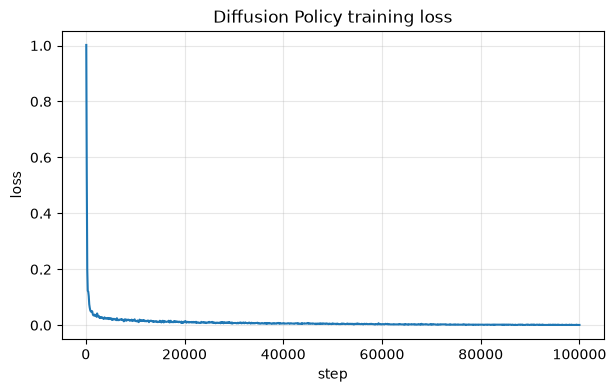

In [6]:
# 실제 로컬 학습 로그에서 추출한 CSV로 그리기 (W&B CSV 내보내기는 사용하지 않음)
# CSV 형식 가정: 첫 열 step, 둘째 열 loss (열 이름은 본인 파일에 맞게 수정)
import os

CSV_PATH = "images/loss_hw4.csv"
if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
    plt.figure(figsize=(7, 4))
    plt.plot(df.iloc[:, 0], df.iloc[:, 1])
    plt.xlabel("step"); plt.ylabel("loss"); plt.title("Diffusion Policy training loss")
    plt.grid(alpha=0.3); plt.show()
else:
    print("CSV 없음 — 위 마크다운의 이미지로 대체")

In [7]:
# [작성] 학습 종료 시점의 손실 (학습 로그 마지막 줄에서 확인)
# Diffusion Policy는 노이즈 예측 오차(MSE)를 loss로 출력한다
dp_final_loss = 0.001  # 실제 100,000스텝 로그 표시값(소수 셋째 자리 반올림)
print("Diffusion Policy 최종 loss:", dp_final_loss)

print("노이즈 예측 MSE이며 관절각 오차 또는 작업 성공률이 아닙니다.")


Diffusion Policy 최종 loss: 0.001
노이즈 예측 MSE이며 관절각 오차 또는 작업 성공률이 아닙니다.


## 3. 실로봇 평가 (조건별 10회)

### 3-1. 평가 프로토콜
1. 과제 3에서 표시한 물체 시작 위치 10곳을 그대로 쓴다. **세 조건 모두 이 10곳을 같은 순서로** 사용한다. (에피소드 0 = 위치 1)
2. 조명, 카메라 위치, 로봇 시작 자세를 데이터 수집 때와 같게 맞춘다.
3. 성공 기준은 과제 3과 같게 두고 아래에 다시 적는다. 평가 도중 바꾸지 않는다.

`[작성]` 성공 기준
- 성공:
- 실패:
- 에피소드 제한 시간(초):
- ACT 평가 결과 재사용 여부 (재사용 / 다시 평가)와 이유:

### 3-2. 평가 명령어
평가는 `lerobot-rollout`으로 한다.
- `--strategy.type=episodic`은 `lerobot-record`처럼 에피소드 단위로 녹화하고 에피소드 사이에 리셋 시간을 둔다. `base`는 녹화하지 않으므로 평가로 인정하지 않는다.
- `--dataset.repo_id`는 `rollout_`로 시작해야 하고, 실제 이름에는 녹화 시각이 붙는다. 그 이름을 0절에 적는다.
- `--robot.id`(캘리브레이션 id)와 카메라 이름(`top`, `wrist`)은 학습 데이터셋과 같아야 한다. 다르면 시작 단계에서 카메라 불일치 오류가 난다.
- `--teleop.*`는 선택 사항이다. 주면 리셋 시간에 리더 암으로 로봇을 되돌릴 수 있다.
- 키보드: `→` 현재 에피소드 조기 종료, `←` 현재 에피소드 폐기 후 다시 녹화, `ESC` 세션 종료. `←`로 다시 녹화한 회차는 결과 `note`에 이유를 적는다.
- `--policy.<이름>=값`을 주면 불러온 정책 설정 위에 덮어쓴다(재학습 불필요).
- Diffusion Policy는 추론이 무겁다. GPU가 있는 PC에서 돌리고, 필요하면 `--device=cuda`를 명시한다.

`[작성]` 평가에 실제로 사용한 `lerobot-rollout` 명령어를 붙여 넣는다. DP (DDIM 10)은 같은 정책에 추론 설정만 덮어써서 평가한다. ACT를 다시 평가했다면 그 명령어도 함께 붙여 넣는다.

```bash
# DP (DDPM)
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=${HF_USER}/diffusion_pick-cube \
  --robot.type=so101_follower \
  --robot.port=/dev/ttyACM0 \
  --robot.id=my_follower \
  --robot.cameras="{ top: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 30}, wrist: {type: opencv, index_or_path: 2, width: 640, height: 480, fps: 30}}" \
  --teleop.type=so101_leader \
  --teleop.port=/dev/ttyACM1 \
  --teleop.id=my_leader \
  --dataset.repo_id=${HF_USER}/rollout_diffusion_pick-cube \
  --dataset.single_task="Pick up the cube and put it in the box." \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=30 \
  --dataset.reset_time_s=15

# DP (DDIM 10)
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=${HF_USER}/diffusion_pick-cube \
  --policy.noise_scheduler_type=DDIM \
  --policy.num_inference_steps=10 \
  --robot.type=so101_follower \
  --robot.port=/dev/ttyACM0 \
  --robot.id=my_follower \
  --robot.cameras="{ top: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 30}, wrist: {type: opencv, index_or_path: 2, width: 640, height: 480, fps: 30}}" \
  --teleop.type=so101_leader \
  --teleop.port=/dev/ttyACM1 \
  --teleop.id=my_leader \
  --dataset.repo_id=${HF_USER}/rollout_diffusion_pick-cube_ddim10 \
  --dataset.single_task="Pick up the cube and put it in the box." \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=30 \
  --dataset.reset_time_s=15
```

**이번 시뮬레이션 평가의 실제 프로토콜(3-1)**
- 성공: 수업의 `active_fruit_on_plate` 판정을 만족하고, 측정 그리퍼 각도≥0.85rad, TCP와 물체 거리≥4.5cm, 물체 속도<5cm/s인 상태가 연속15프레임(0.5초) 유지되는 경우.
- 실패: 제한 시간 안에 위 놓기·안정화 조건을 만족하지 못한 경우. 과일을 잡은 채 접시 위를 지나가는 상태를 최종 놓기 성공으로 세지 않도록 했다. 수업의 원래 접시 판정도 별도로 기록했으며 이번 기본 30회의 성공 횟수는 두 판정에서 같았다.
- 제한 시간: **30초의 시뮬레이션 시간**(30Hz 제어, 최대900스텝). 추론 계산 중에는 물리가 대기하므로 실제 벽시계 시간 30초 평가와 다르다.
- ACT 재사용 여부: **다시 학습·다시 평가**. 과제 3의 실물 큐브와 환경·데이터가 달라 당시 0% 결과를 섞지 않았다.
- 비교 배치: seed424200~424209의 새 배치10개를 동일 순서로 사용했다. 딸기3·오렌지3·레몬2·바나나2회이며, 과일 XY 오프셋은 ±2.5cm, 접시 X는±2.5cm·Y는-2.5~1cm에서 한 번 정해 고정했다. 베이스·조명·시작 관절각은 기본값이다.
- 과일·접시·로봇의 실현 초기 상태를 세 조건 간 대조했다. 최대 차이는 약0.0104mm로 검사 허용 오차0.1mm 안이었다. 실패 회차도 보존했고 실패를 성공 회차로 재녹화하여 대체하지 않았다.

**실제 실행한 명령(3-2)**

원본에 남겨 둔 `lerobot-rollout` 명령은 실로봇용 수업 예시이다. 이번에는 실물 모터에 연결하지 않고 시뮬레이션 전용 실행기로 같은 형식의 LeRobot 데이터셋을 기록했다. 이 실행기를 `lerobot-rollout`으로 실행했다고 기재하지 않는다.

```powershell
.\.venv-lerobot\Scripts\python.exe -u assignment_4\simulation\run_evaluation.py --tag eval-release-20261120
# 기본 3조건×10회 + DP 두 조건의 반응성 각3회

.\.venv-lerobot\Scripts\python.exe -u assignment_4\simulation\run_evaluation.py --tag eval-release-20261120 --resume --conditions act --reactivity-only
# 동일 배치의 ACT 반응성 참고3회 추가
```

실제 모델 경로는 `outputs/train/hw4_sim100_act_20261119_sim100/train/checkpoints/100000/pretrained_model` 및 `outputs/train/hw4_sim100_diffusion_20261119_sim100/train/checkpoints/100000/pretrained_model`이다. DP DDPM은 학습한 DDPM100을 그대로 사용했고, DDIM10은 **같은 DP 가중치**에서 `noise_scheduler_type=DDIM`, `num_inference_steps=10`만 바꿔 불러왔다. 세 조건 모두 front·wrist 영상을 정책에 입력했고 실제 관절상태·예측 행동·성공 플래그를 녹화했다.

| 조건 | 성공 | 새 청크 예측 평균 | 행동 출력 호출 평균 | 관절 jerk RMS 평균(rad/s³) |
|---|---:|---:|---:|---:|
| ACT chunk100 | 9/10 | 20.50ms | 0.80ms | 119.37 |
| DP DDPM100 | 8/10 | 1276.44ms | 163.46ms | 123.29 |
| DP DDIM10 | 7/10 | 118.78ms | 17.55ms | 164.05 |

CUDA 예열 후 동기화를 포함해 정책 전·후처리와 새 청크 예측 시간을 측정했다. 새 청크 예측과 큐에서 기존 행동을 꺼내는 호출을 구분했으며, 표의 시간에는 별도 시뮬 프로세스와의 통신·영상 녹화 시간이 포함되지 않는다. jerk는 실제 팔5관절의 시뮬 시간 궤적에서 계산한 참고 지표로 주관적 부드러움 1~5점을 대체하지 않는다.

![평가 비교](images/hw4_comparison.png)


In [8]:
# 평가 데이터셋 메타데이터 확인 — 조건별 에피소드 수가 10이어야 한다
eval_infos = {}
for k in CONDITIONS:
    info = load_json(EVAL_DATASETS[k], "meta/info.json", repo_type="dataset")
    eval_infos[k] = info
    if info:
        n_ep = info.get("total_episodes")
        print(f"{LABELS[k]:<14} 에피소드 {n_ep}개, 프레임 {info.get('total_frames')}, fps {info.get('fps')}  ->",
              "통과" if n_ep == 10 else f"불일치 ({n_ep}개)")
for _k, _rid in EVAL_DATASETS.items():
    _ok = _rid.split("/", 1)[-1].startswith("rollout_")
    print(f" {_k} 이름 규칙:", "통과" if _ok else "rollout_로 시작하지 않음 — lerobot-rollout으로 녹화했는지 확인")

print("rollout_ 검사는 이름 규칙 확인입니다. 실제 수집은 시뮬 전용 평가기로 수행했으며 HF 데이터는 비공개로 업로드했습니다.")


C:\Users\kyhyg\OneDrive\바탕 화면\4학년\2학기\로봇제어인공지능01김성제\.venv-lerobot\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\kyhyg\OneDrive\바탕 화면\4학년\2학기\로봇제어인공지능01김성제\tmp\hw4-hub-cache\datasets--alohateam1423--rollout_hw4_sim_act. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


ACT (chunk100) 에피소드 10개, 프레임 5187, fps 30  -> 통과


C:\Users\kyhyg\OneDrive\바탕 화면\4학년\2학기\로봇제어인공지능01김성제\.venv-lerobot\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\kyhyg\OneDrive\바탕 화면\4학년\2학기\로봇제어인공지능01김성제\tmp\hw4-hub-cache\datasets--alohateam1423--rollout_hw4_sim_dp. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


DP (DDPM)      에피소드 10개, 프레임 6166, fps 30  -> 통과


DP (DDIM 10)   에피소드 10개, 프레임 6102, fps 30  -> 통과
 act 이름 규칙: 통과
 dp 이름 규칙: 통과
 dp_ddim10 이름 규칙: 통과
rollout_ 검사는 이름 규칙 확인입니다. 실제 수집은 시뮬 전용 평가기로 수행했으며 HF 데이터는 비공개로 업로드했습니다.


C:\Users\kyhyg\OneDrive\바탕 화면\4학년\2학기\로봇제어인공지능01김성제\.venv-lerobot\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\kyhyg\OneDrive\바탕 화면\4학년\2학기\로봇제어인공지능01김성제\tmp\hw4-hub-cache\datasets--alohateam1423--rollout_hw4_sim_dp_ddim10. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


### 3-3. 회차별 결과
`[작성]` 아래 `results`를 실제 결과로 채운다. ACT 평가를 재사용했다면 과제 3의 결과를 그대로 옮긴다.
- `smooth`: 동작의 부드러움을 1(덜컥거림·떨림 심함) ~ 5(매우 부드러움)로 평가
- `note`: 관찰 내용. **실패한 경우 원인을 구체적으로** 적는다. 추론 때문에 동작이 멈칫하는 구간이 보이면 함께 적는다. (예: "큐브 위치를 놓침", "다시 추론할 때마다 팔이 잠깐 멈춤", "파지 직전 좌우로 머뭇거림")

In [9]:
def blank():
    return [{"episode": i, "position": i + 1, "success": None, "smooth": None, "note": ""} for i in range(10)]

results = {'act': [{'episode': 0,
          'position': 1,
          'success': True,
          'smooth': 4,
          'note': 'Strawberry: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'},
         {'episode': 1,
          'position': 2,
          'success': True,
          'smooth': 4,
          'note': 'Orange: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'},
         {'episode': 2,
          'position': 3,
          'success': True,
          'smooth': 4,
          'note': 'Lemon: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'},
         {'episode': 3,
          'position': 4,
          'success': True,
          'smooth': 4,
          'note': 'Banana: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'},
         {'episode': 4,
          'position': 5,
          'success': True,
          'smooth': 4,
          'note': 'Strawberry: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'},
         {'episode': 5,
          'position': 6,
          'success': True,
          'smooth': 4,
          'note': 'Orange: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'},
         {'episode': 6,
          'position': 7,
          'success': True,
          'smooth': 4,
          'note': 'Lemon: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'},
         {'episode': 7,
          'position': 8,
          'success': False,
          'smooth': 4,
          'note': 'Banana: 바나나를 안정적으로 잡지 못해 작업대에 남았고, 빈 그리퍼가 접시 쪽으로 이동한 뒤 재접근했으나 30초 내 완료하지 못했다.'},
         {'episode': 8,
          'position': 9,
          'success': True,
          'smooth': 4,
          'note': 'Strawberry: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'},
         {'episode': 9,
          'position': 10,
          'success': True,
          'smooth': 4,
          'note': 'Orange: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'}],
 'dp': [{'episode': 0,
         'position': 1,
         'success': True,
         'smooth': 2,
         'note': 'Strawberry: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'},
        {'episode': 1,
         'position': 2,
         'success': False,
         'smooth': 2,
         'note': 'Orange: 오렌지 옆으로 파지 위치가 빗나가 충분히 들어 올리지 못했고, 빈 그리퍼가 접시 쪽으로 이동했다. 이후 재접근했으나 30초 내 완료하지 '
                 '못했다.'},
        {'episode': 2,
         'position': 3,
         'success': True,
         'smooth': 2,
         'note': 'Lemon: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'},
        {'episode': 3,
         'position': 4,
         'success': True,
         'smooth': 2,
         'note': 'Banana: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'},
        {'episode': 4,
         'position': 5,
         'success': True,
         'smooth': 2,
         'note': 'Strawberry: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'},
        {'episode': 5,
         'position': 6,
         'success': True,
         'smooth': 2,
         'note': 'Orange: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'},
        {'episode': 6,
         'position': 7,
         'success': True,
         'smooth': 2,
         'note': 'Lemon: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'},
        {'episode': 7,
         'position': 8,
         'success': True,
         'smooth': 2,
         'note': 'Banana: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'},
        {'episode': 8,
         'position': 9,
         'success': True,
         'smooth': 2,
         'note': 'Strawberry: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'},
        {'episode': 9,
         'position': 10,
         'success': False,
         'smooth': 2,
         'note': 'Orange: 오렌지 주변에 반복 접근·하강했으나 파지하지 못했다. 물체는 작업대에 남고 그리퍼만 접시 쪽으로 이동했다.'}],
 'dp_ddim10': [{'episode': 0,
                'position': 1,
                'success': True,
                'smooth': 2,
                'note': 'Strawberry: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'},
               {'episode': 1,
                'position': 2,
                'success': False,
                'smooth': 2,
                'note': 'Orange: 오렌지 파지를 반복 시도했으나 안정적으로 운반하지 못했고, 물체가 작업대에 남아 제한 시간이 끝났다.'},
               {'episode': 2,
                'position': 3,
                'success': True,
                'smooth': 2,
                'note': 'Lemon: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'},
               {'episode': 3,
                'position': 4,
                'success': True,
                'smooth': 2,
                'note': 'Banana: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'},
               {'episode': 4,
                'position': 5,
                'success': True,
                'smooth': 2,
                'note': 'Strawberry: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'},
               {'episode': 5,
                'position': 6,
                'success': True,
                'smooth': 2,
                'note': 'Orange: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'},
               {'episode': 6,
                'position': 7,
                'success': True,
                'smooth': 2,
                'note': 'Lemon: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'},
               {'episode': 7,
                'position': 8,
                'success': True,
                'smooth': 2,
                'note': 'Banana: 과일을 놓고 접시 범위 안에서 0.5초 안정화했다.'},
               {'episode': 8,
                'position': 9,
                'success': False,
                'smooth': 2,
                'note': 'Strawberry: 딸기 앞에 접근한 뒤 동작이 정체되어 파지·운반으로 진행하지 못했다. 물체를 들어 올리지 못한 채 제한 시간이 '
                        '끝났다.'},
               {'episode': 9,
                'position': 10,
                'success': False,
                'smooth': 2,
                'note': 'Orange: 오렌지 주변에 접근했으나 파지하지 못했고, 빈 그리퍼만 접시 쪽으로 이동했다.'}]}
# 예시: results["dp"][0] = {"episode": 0, "position": 1, "success": True, "smooth": 4, "note": "다시 추론할 때 짧게 멈추지만 안정적으로 파지"}

res_df = pd.concat([pd.DataFrame(v).assign(condition=k) for k, v in results.items()], ignore_index=True)
summary = (res_df.assign(success=res_df["success"].astype(float))
           .groupby("condition", sort=False)
           .agg(success_rate=("success", "mean"), mean_smooth=("smooth", "mean")))
summary["success_rate"] = (summary["success_rate"] * 100).round(0)
summary.index = [LABELS[k] for k in summary.index]
summary

print("부드러움: 작성자의 영상 검수 점수 ACT 4점, DDPM·DDIM10 각각 2점을 조건별 10회에 동일 적용했습니다. 회차별 독립 채점값은 아닙니다.")

display(summary)


부드러움: 작성자의 영상 검수 점수 ACT 4점, DDPM·DDIM10 각각 2점을 조건별 10회에 동일 적용했습니다. 회차별 독립 채점값은 아닙니다.


,success_rate,mean_smooth
ACT (chunk100),90.0,4.0
DP (DDPM),80.0,2.0
DP (DDIM 10),70.0,2.0


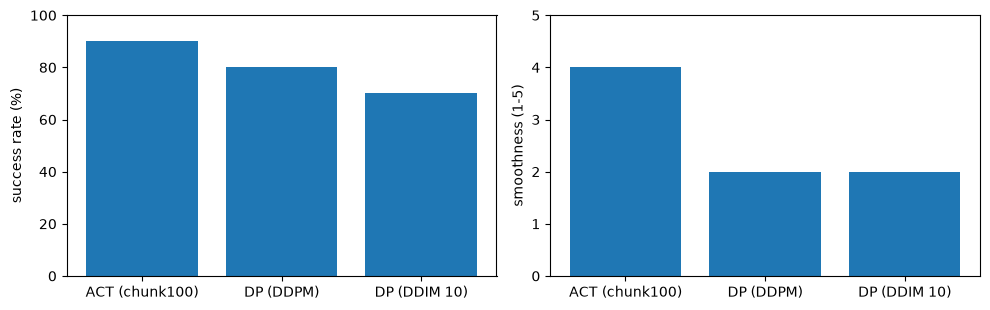

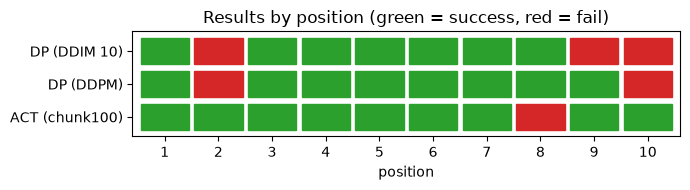

In [10]:
# 조건별 성공률과 부드러움
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
labels = list(summary.index)
axes[0].bar(labels, summary["success_rate"]); axes[0].set_ylim(0, 100)
axes[0].set_ylabel("success rate (%)")
if summary["mean_smooth"].notna().any():
    axes[1].bar(labels, summary["mean_smooth"])
else:
    axes[1].text(0.5, 0.5, "Pending video review", ha="center", va="center", transform=axes[1].transAxes)
axes[1].set_ylim(0, 5)
axes[1].set_ylabel("smoothness (1-5)")
plt.tight_layout(); plt.show()

# 위치별 성공/실패 (행 = 조건, 열 = 물체 위치)
fig, ax = plt.subplots(figsize=(7, 2.0))
for row, k in enumerate(CONDITIONS):
    for r in results[k]:
        c = "tab:green" if r["success"] else ("tab:red" if r["success"] is False else "lightgray")
        ax.add_patch(plt.Rectangle((r["position"] - 0.45, row - 0.4), 0.9, 0.8, color=c))
ax.set_xlim(0.4, 10.6); ax.set_ylim(-0.6, len(CONDITIONS) - 0.4)
ax.set_xticks(range(1, 11)); ax.set_yticks(range(len(CONDITIONS)))
ax.set_yticklabels([LABELS[k] for k in CONDITIONS]); ax.set_xlabel("position")
ax.set_title("Results by position (green = success, red = fail)")
plt.tight_layout(); plt.show()

### 3-4. 반응성 테스트
과제 3의 3-4와 같은 방법으로, DP (DDPM)과 DP (DDIM 10)을 각각 3회씩 추가로 시도한다. 로봇이 물체를 향해 움직이기 시작한 직후 **물체를 약 5 cm 옮기고**, 로봇이 새 위치를 따라가는지 관찰한다. (녹화는 선택, 성공률 집계에는 넣지 않음) ACT는 과제 3의 반응성 테스트 결과와 비교한다.

반응성 테스트는 녹화가 필요 없으므로 `--strategy.type=base`로 돌린다. `base`는 `--dataset.*` 대신 `--task="..."`와 `--duration=<초>`를 받는다. DDIM 10은 `--policy.noise_scheduler_type=DDIM --policy.num_inference_steps=10`을 함께 준다.

`[작성]` 아래 `reactivity`를 채운다.

**실제 수행·판정 방법**

기본 평가의 오렌지 배치(위치2·6·10번)를 재사용했다. TCP가 시작점에서2cm 이동하면 물체를 월드X 방향으로5cm 옮기고 속도를0으로 설정했다. 새 목표좌표는 성공 판정·측정에만 사용했으며 정책에는 카메라 영상과 관절 상태만 입력했다.

여기서 `followed=True`는 **부분 추종의 분석용 기준**이다. 이동 전 동일 배치의 접근 궤적과 비교해 새 방향으로2cm 이상 보정하고, 새 목표까지의 XY 거리가4cm 이내이며 기존 궤적보다1cm 이상 개선된 경우로 정했다. 첫 파지 높이 접근(없으면 초기12초 내 낮은 접근 위치)을 비교했다. 이는 과제에 정해진 정량 문턱이 아니라 이번 시뮬레이션 관찰을 정리하기 위한 기준이며, 완전한 위치 추종이나 파지·놓기 성공을 뜻하지 않는다.

DP 두 조건 모두 부분 추종3/3이었지만 이동 후 놓기 성공은0/3이었다. ACT는 부분 추종2/3, 이동 후 놓기2/3이었다. 반응성 배치의 이동 전 성공은 ACT3/3, DP·DDIM10 각각1/3이므로, 원래 실패한 배치도 포함된 점을 해석에 반영한다. 전체39회·24,693프레임의 데이터·영상 개수와 종료 플래그, 6차원 상태·실행 행동의 일치를 검사했다.

![반응성 궤적](images/hw4_reactivity.png)


In [11]:
reactivity = {'dp': [{'trial': 0,
         'followed': True,
         'note': '새 방향으로 약33.1mm 부분 보정, 접근 시 새 목표 XY 오차 약25.7mm. 이동 후 파지·놓기는 실패했다.'},
        {'trial': 1,
         'followed': True,
         'note': '새 방향으로 약29.5mm 부분 보정, 접근 시 새 목표 XY 오차 약25.2mm. 이동 후 파지·놓기는 실패했다.'},
        {'trial': 2,
         'followed': True,
         'note': '새 방향으로 약26.0mm 부분 보정, 접근 시 새 목표 XY 오차 약25.7mm. 이동 후 파지·놓기는 실패했다.'}],
 'dp_ddim10': [{'trial': 0,
                'followed': True,
                'note': '새 방향으로 약30.1mm 부분 보정, 접근 시 새 목표 XY 오차 약25.7mm. 이동 후 파지·놓기는 실패했다.'},
               {'trial': 1,
                'followed': True,
                'note': '새 방향으로 약27.8mm 부분 보정, 접근 시 새 목표 XY 오차 약25.2mm. 이동 후 파지·놓기는 실패했다.'},
               {'trial': 2,
                'followed': True,
                'note': '새 방향으로 약27.1mm 부분 보정, 접근 시 새 목표 XY 오차 약26.5mm. 이동 후 파지·놓기는 실패했다.'}]}
react_df = pd.concat([pd.DataFrame(v).assign(condition=LABELS[k]) for k, v in reactivity.items()], ignore_index=True)
print(react_df.groupby("condition", sort=False)["followed"].apply(lambda s: f"{int(s.fillna(False).sum())}/3"))
react_df

print("추가 ACT 참고: 부분 추종 2/3, 이동 후 놓기 2/3. 반응성 결과는 기본 10회 성공률에 합산하지 않습니다.")

display(react_df)


condition
DP (DDPM)       3/3
DP (DDIM 10)    3/3
Name: followed, dtype: object
추가 ACT 참고: 부분 추종 2/3, 이동 후 놓기 2/3. 반응성 결과는 기본 10회 성공률에 합산하지 않습니다.


,trial,followed,note,condition
0,0,True,"새 방향으로 약33.1mm 부분 보정, 접근 시 새 목표 XY 오차 약25.7mm....",DP (DDPM)
1,1,True,"새 방향으로 약29.5mm 부분 보정, 접근 시 새 목표 XY 오차 약25.2mm....",DP (DDPM)
2,2,True,"새 방향으로 약26.0mm 부분 보정, 접근 시 새 목표 XY 오차 약25.7mm....",DP (DDPM)
3,0,True,"새 방향으로 약30.1mm 부분 보정, 접근 시 새 목표 XY 오차 약25.7mm....",DP (DDIM 10)
4,1,True,"새 방향으로 약27.8mm 부분 보정, 접근 시 새 목표 XY 오차 약25.2mm....",DP (DDIM 10)
5,2,True,"새 방향으로 약27.1mm 부분 보정, 접근 시 새 목표 XY 오차 약26.5mm....",DP (DDIM 10)


### 3-5. 평가 영상
`[작성]` 웹 뷰어(https://huggingface.co/spaces/lerobot/visualize_dataset)에 평가 데이터셋 repo_id를 넣어 재생되는지 확인한다.
ACT와 Diffusion Policy의 **동작 차이가 잘 드러나는 장면**을 조건별로 하나씩 GIF로 만들어 `images/`에 올리고 아래에 삽입한다. (예: ACT의 청크 경계 튐, DP의 추론 중 멈칫함, DDIM 10의 궤적 흔들림)

![act](images/hw4_act.gif)
![dp](images/hw4_dp.gif)
![dp_ddim10](images/hw4_dp_ddim10.gif)

위 GIF는 세 정책 모두 **같은 첫 배치(딸기)**의 마지막8초를 사용했다. 원본 영상은 front·wrist 두 시점의30fps이고, GIF는 시뮬 시간 기준으로 재생한다. 따라서 GPU 추론을 기다리는 실제 벽시계 대기를 GIF의 프레임 간격으로 재현한 영상은 아니며, 그 대기시간은3-2의 측정값으로 비교한다. HF 데이터는 비공개로 업로드했으며, 웹 뷰어 재생은 아직 확인하지 않았다.


## 4. 고찰
`[작성]` 각 질문에 3~5문장으로 답한다. 가능하면 3절의 수치나 영상 장면을 근거로 든다.

**4-1. 가설 검증** — 성공률이 가장 높은 조건은 무엇이었는가? 1-2의 가설과 비교해, 맞았다면 왜 맞았고 달랐다면 왜 달랐는지 설명하라.

학습 전 별도 가설 기록이 없어 사전 가설을 검증한 실험이라고 표현하지 않았다. 실제 성공률은 ACT90%, DDPM80%, DDIM10 70%로 ACT가 가장 높았다. Diffusion의 분포 표현 능력이 이론적 장점이어도, 일관된 스크립트 시연100개에서 자동으로 더 높은 성공률로 이어지는 것은 아니었다. 각10회의 작은 표본이므로 일반적인 정책 우열을 확정할 수 없다.

**4-2. 행동 생성 방식의 차이** — ACT와 Diffusion Policy의 동작에서 관찰된 차이(궤적의 부드러움, 머뭇거림, 파지 위치 선택 등)를 두 정책의 행동 생성 방식(회귀와 샘플링)으로 설명하라.

ACT는 생성한100개 행동을 실행하고, Diffusion은 노이즈에서 행동을 생성한 뒤8개 행동마다 다시 추론했다. 작성자의 영상 검수에서 ACT는4점, DDPM·DDIM10은각2점으로 ACT가 더 부드럽게 평가됐으며, 조건별 대표 점수를 각10회에 동일 적용했다. ACT는 바나나1회, DDPM은 오렌지2회, DDIM10은 오렌지2회·딸기1회에서 실패했고, 검수한 장면에서는 불안정한 파지·빈 그리퍼의 운반·접근 후 정체가 관찰됐다. 평균 관절 jerk RMS는119.37, 123.29, 164.05rad/s³였지만, 이는 주관적 점수나 행동 생성 원인의 직접 증거가 아니다. 시퀀스 생성 방식과 관측 반영 주기가 영향을 줄 수 있으나, 관찰된 차이를 회귀·샘플링 구조 하나만으로 단정하지 않는다.

**4-3. denoising 횟수와 실시간성** — DDIM 10에서 성공률, 부드러움, 추론 때문에 멈칫하는 정도가 DDPM과 비교해 어떻게 달라졌는가? 실시간 제어 관점에서 적절한 denoising 횟수는 얼마라고 보는가?

같은 DP 가중치에서 DDPM100을 DDIM10으로 바꾸자 새 청크 추론 평균이1276.44ms에서118.78ms로 약10.7배 빨라졌다. 이번 성공은8/10에서7/10으로 줄고 jerk 참고값은 커졌지만, 주관적 부드러움은 두 조건 모두2점으로 같아 점수상 개선은 없었다. DP의8스텝 실행 구간은30fps에서약267ms이므로 DDIM10의 계산시간은 그 안에 들어가지만 DDPM100은 훨씬 길었다. 다만 동기식 시뮬레이터는 추론 중 물리가 대기하고 검수 영상도 그 벽시계 대기를 포함하지 않으므로, 영상 점수로 추론 중 멈칫함이나 실로봇30Hz 제어까지 검증했다고 해석하지 않는다. 이 조건에서는10스텝을 속도 개선 후보로 볼 수 있지만, 중간 횟수와 비동기 실행을 추가 비교하지 않아 최적값이라고 단정할 수 없다.

**4-4. 반응성** — Diffusion Policy는 `n_action_steps`마다 다시 추론한다. 반응성 테스트 결과를 과제 3의 ACT 결과와 비교하고, 차이를 다시 추론하는 주기로 설명하라.

부분 추종 기준으로 DP 두 조건은각3/3, 새로 평가한 ACT는2/3이었고, 이동 후 놓기는각0/3·0/3·2/3이었다. DP의 재추론 주기는8/30≈0.267초, ACT는100/30≈3.33초로 DP가 시뮬 시간상 더 자주 관측을 반영했지만 그것만으로 작업 복구가 보장되지는 않았다. 이동 전 동일 오렌지 배치의 성공도 ACT3/3, DP 두 조건은각1/3이어서 반응성 실패 전부를 물체 이동 탓으로 볼 수 없다. 학습 데이터의 시작 관절각은 고정이고 중간 물체 이동 시연도 없어 복구 상태의 시연 부족이 한계일 가능성이 있다. 실제 벽시계에서의 반응 지연과 시뮬 궤적상의 위치 보정을 구분하여 해석했다.

**4-5. 내 태스크에 맞는 정책** — 학습 시간, 추론 속도, 성공률을 함께 고려할 때 본인 태스크에는 ACT와 Diffusion Policy 중 무엇이 적합한가? 그 정책을 더 개선하려면 무엇을 바꿔 보겠는가?

이번10회에서는 성공률90%와 새 청크 약20.5ms의 ACT가 실용적인 기준선이었다. 측정 학습시간은 ACT9시간20분49초, DP8시간37분7초였지만 병렬 학습으로 GPU 자원을 공유했으므로 단독 학습 비용의 우열을 뜻하지 않는다. Diffusion을 사용할 경우에는 DDIM10의 속도 이득을 검토하되, 오렌지 파지 오차와 줄어든 성공률을 함께 개선해야 한다. 후속 개선으로 실패 배치의 정확한 파지 시연, 안전한 시작 관절각 변화, 중간 상태의 재접근·복구 시연을 추가하고 별도 초기 배치에서 다시 평가하는 방법을 고려할 수 있다.

## 제출 전 체크리스트
아래 셀을 실행해 모든 항목이 통과하는지 확인한 뒤 커밋한다.

In [12]:
def repo_ok(rid, rtype):
    if not HUB_UPLOAD_CONFIRMED:
        return False
    try:
        info = api.repo_info(rid, repo_type=rtype, token=False)
        return not info.private
    except Exception:
        return False

def file_ok(rid, fname, rtype):
    if not HUB_UPLOAD_CONFIRMED:
        return False
    try:
        info = HfApi(token=False).repo_info(rid, repo_type=rtype, files_metadata=True)
        return not info.private and not info.gated and any(s.rfilename == fname and s.size for s in info.siblings)
    except Exception:
        return False

check_items = {
    "LeRobot 0.6.x 환경": bool(LEROBOT_VERSION) and LEROBOT_VERSION.startswith("0.6."),
    "평가 데이터셋 이름 rollout_로 시작 (시뮬 전용 평가기 사용)": all(
        r.split("/", 1)[-1].startswith("rollout_") for r in EVAL_DATASETS.values()),
    "학습 데이터셋 접근 가능 (public)": repo_ok(TRAIN_DATASET, "dataset"),
    "Diffusion Policy 업로드됨 (config.json, model.safetensors)": (
        file_ok(DP_POLICY_REPO, "config.json", "model") and file_ok(DP_POLICY_REPO, "model.safetensors", "model")),
    "ACT와 같은 학습 데이터셋 사용 (1-3)": bool(same_dataset),
}
for k in CONDITIONS:
    check_items[f"{LABELS[k]} 평가 데이터셋 에피소드 10개"] = bool(eval_infos.get(k)) and eval_infos[k].get("total_episodes") == 10
    check_items[f"{LABELS[k]} 회차별 결과 10개 입력"] = all(r["success"] is not None for r in results[k])
    check_items[f"{LABELS[k]} 실패 회차에 원인 기재"] = all(r["note"].strip() for r in results[k] if r["success"] is False)
check_items["반응성 테스트 6회 입력"] = all(r["followed"] is not None for v in reactivity.values() for r in v)

check_items["부드러움 1~5점 입력"] = all(
    r["smooth"] is not None for rows in results.values() for r in rows)
check_items["세 평가 데이터셋 HF 공개 업로드"] = all(repo_ok(rid, "dataset") for rid in EVAL_DATASETS.values())

for k, v in check_items.items():
    print(("[통과] " if v else "[미흡] ") + k)
print("\n모두 통과" if all(check_items.values()) else "\n미흡 항목을 보완한 뒤 커밋할 것")

print("\n모델 공개 업로드와 소유자 인증을 통한 데이터 확인은 완료했습니다. 학습·평가 데이터는 비공개이므로 public 조건은 미충족입니다.")


[통과] LeRobot 0.6.x 환경
[통과] 평가 데이터셋 이름 rollout_로 시작 (시뮬 전용 평가기 사용)
[미흡] 학습 데이터셋 접근 가능 (public)
[통과] Diffusion Policy 업로드됨 (config.json, model.safetensors)
[통과] ACT와 같은 학습 데이터셋 사용 (1-3)
[통과] ACT (chunk100) 평가 데이터셋 에피소드 10개
[통과] ACT (chunk100) 회차별 결과 10개 입력
[통과] ACT (chunk100) 실패 회차에 원인 기재
[통과] DP (DDPM) 평가 데이터셋 에피소드 10개
[통과] DP (DDPM) 회차별 결과 10개 입력
[통과] DP (DDPM) 실패 회차에 원인 기재
[통과] DP (DDIM 10) 평가 데이터셋 에피소드 10개
[통과] DP (DDIM 10) 회차별 결과 10개 입력
[통과] DP (DDIM 10) 실패 회차에 원인 기재
[통과] 반응성 테스트 6회 입력
[통과] 부드러움 1~5점 입력
[미흡] 세 평가 데이터셋 HF 공개 업로드

미흡 항목을 보완한 뒤 커밋할 것

모델 공개 업로드와 소유자 인증을 통한 데이터 확인은 완료했습니다. 학습·평가 데이터는 비공개이므로 public 조건은 미충족입니다.
